# Laboratorio #3 - Parte A
## INF0157 - Sistemas

**Autor:** Renato Carrasco  
**Fecha:** 19 de Noviembre, 2025

---

## Contenido de la Parte A:
1. **Punto 1**: Aplique KMeans de sklearn python
2. **Punto 2**: Aplique MeanShift de sklearn python
3. **Punto 3**: Regresión Lineal (Tabla de Pesos y Alturas)
4. **Punto 4**: Distancia del Coseno

# PUNTO 1: KMeans Clustering

## 1.1 Importar librerías para KMeans

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data_loader import DataLoader, print_data_info
from src.clustering.kmeans_model import KMeansModel
from src.utils.visualization import Visualizer

print("✅ Librerías para KMeans importadas correctamente")

✅ Librerías para KMeans importadas correctamente


## 1.2 Pregunta 1: Cargar datos de entrenamiento A.npy y _.npy

In [2]:
# Cargar datos de entrenamiento
A, labels = DataLoader.load_kmeans_data()

print(f"Datos cargados:")
print(f"  Forma de A: {A.shape}")
print(f"  Forma de labels: {labels.shape}")
print(f"  Primeras 5 filas de A:\n{A[:5]}")
print(f"  Primeras 5 labels: {labels[:5]}")

Datos cargados:
  Forma de A: (1000, 2)
  Forma de labels: (1000,)
  Primeras 5 filas de A:
[[ 7.16624987  6.15093134]
 [ 9.13632418 -6.07520617]
 [ 8.78381595 -6.49214774]
 [ 2.45994105  7.86958895]
 [ 7.7579485   7.05388394]]
  Primeras 5 labels: [0 2 2 1 0]


## 1.3 Pregunta 1: Obtener gráfico de la Figura A (datos originales)

e:\INF\Caro-Proyecto3-Sistemas\notebooks\..\src\utils\visualization.py:42: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


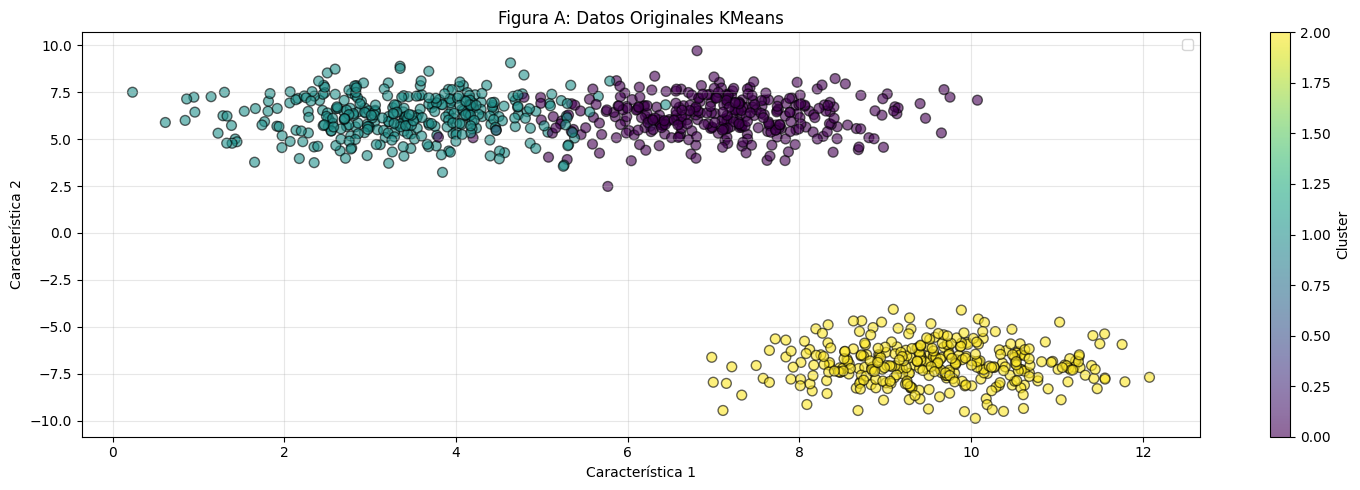

In [3]:
# Graficar datos originales con etiquetas reales
Visualizer.plot_2d_clusters(A, labels, title="Figura A: Datos Originales KMeans")
plt.show()

## 1.4 Pregunta 3: Entrenar modelo KMeans y obtener Clusters y Centroides

In [4]:
# Crear y entrenar el modelo KMeans
kmeans = KMeansModel(n_clusters=3, random_state=42)
kmeans.fit(A)

# Obtener resultados
centroids = kmeans.get_centroids()
predicted_labels = kmeans.get_labels()

print("✅ Modelo KMeans entrenado")
print(f"\nInformación del modelo:")
info = kmeans.get_info()
for key, value in info.items():
    print(f"  {key}: {value}")
print(f"\nCentroides del modelo:")
print(centroids)

✅ Modelo KMeans entrenado

Información del modelo:
  n_clusters: 3
  inertia: 1990.7592362653397
  n_iterations: 3
  centroids_shape: (3, 2)
  n_labels: 3

Centroides del modelo:
[[ 3.34294673  6.21052482]
 [ 9.55006356 -6.98392902]
 [ 7.05781773  6.21327704]]


## 1.5 Pregunta 2: Obtener gráfico de la Figura B (blobs mediante colores)

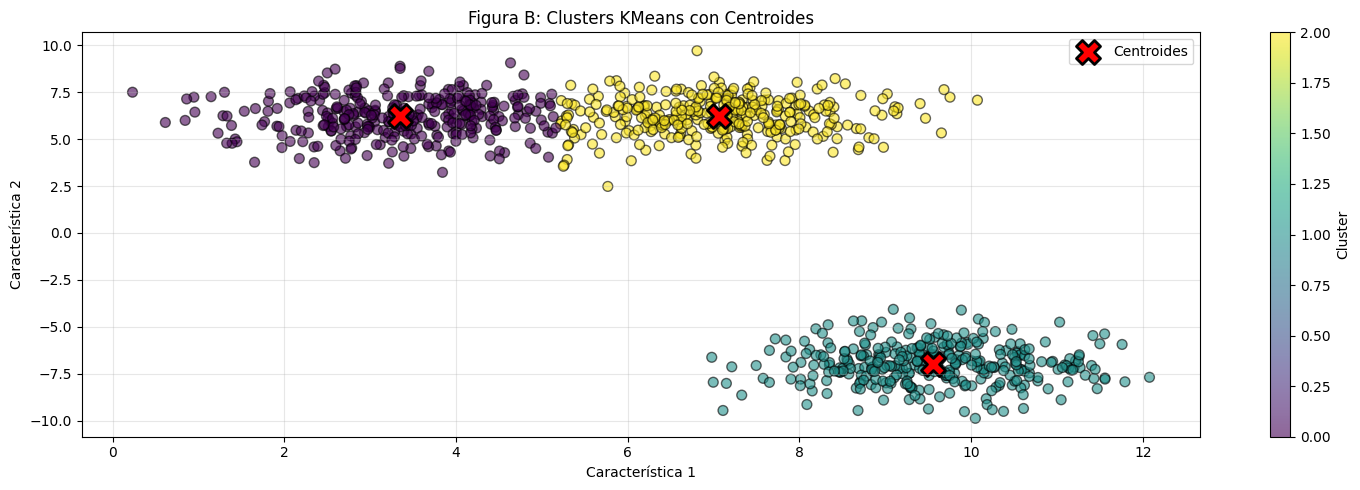

In [5]:
# Graficar clusters con centroides (con marcador de Estrella)
Visualizer.plot_2d_clusters(A, predicted_labels, centroids, 
                            title="Figura B: Clusters KMeans con Centroides")
plt.show()

## 1.6 Figura C: Comparación datos originales vs clusters

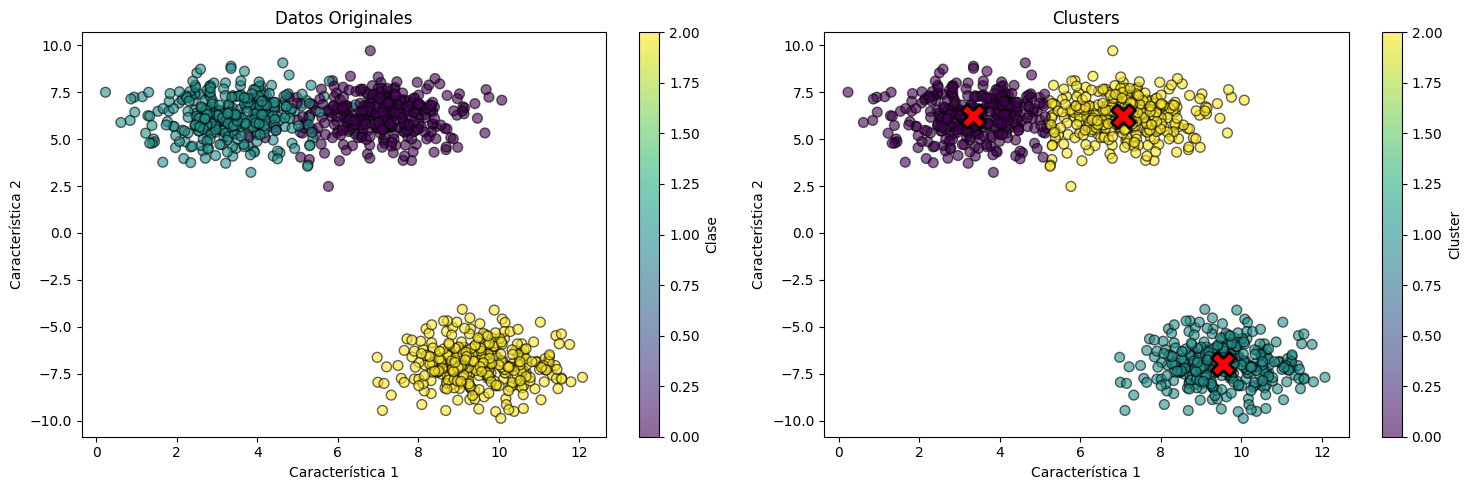

In [6]:
# Graficar comparación original vs clusters
Visualizer.plot_training_vs_clusters(A, labels, A, predicted_labels, centroids)
plt.show()

## 1.7 Pregunta 4: ¿Cuáles son las etiquetas de la data? ¿Cuántos datos son?

In [7]:
# Respuesta a Pregunta 4
print(f"\n{'='*60}")
print(f"RESPUESTA A PREGUNTA 4")
print(f"{'='*60}")

# ¿Cuáles son las etiquetas de la data?
unique_labels_original = np.unique(labels)
print(f"\n1️⃣  ¿Cuáles son las etiquetas de la data?")
print(f"   Las etiquetas originales son: {unique_labels_original}")
print(f"   (Representa {len(unique_labels_original)} clases en los datos)")

# ¿Cuántos datos son?
total_datos = len(A)
print(f"\n2️⃣  ¿Cuántos datos son?")
print(f"   Total de datos: {total_datos} puntos")

# Información adicional por cluster
unique_clusters = np.unique(predicted_labels)
print(f"\n📊 Información de clusters detectados por KMeans:")
print(f"   Clusters identificados: {unique_clusters}")
print(f"   Total de clusters: {len(unique_clusters)}")
print(f"\n   Distribución por cluster:")

for cluster_id in unique_clusters:
    count = np.sum(predicted_labels == cluster_id)
    percentage = (count / len(predicted_labels)) * 100
    centroid = centroids[cluster_id]
    print(f"     Cluster {int(cluster_id)}: {count} puntos ({percentage:.1f}%)")
    print(f"       Centroide: [{centroid[0]:.4f}, {centroid[1]:.4f}]")


RESPUESTA A PREGUNTA 4

1️⃣  ¿Cuáles son las etiquetas de la data?
   Las etiquetas originales son: [0 1 2]
   (Representa 3 clases en los datos)

2️⃣  ¿Cuántos datos son?
   Total de datos: 1000 puntos

📊 Información de clusters detectados por KMeans:
   Clusters identificados: [0 1 2]
   Total de clusters: 3

   Distribución por cluster:
     Cluster 0: 327 puntos (32.7%)
       Centroide: [3.3429, 6.2105]
     Cluster 1: 333 puntos (33.3%)
       Centroide: [9.5501, -6.9839]
     Cluster 2: 340 puntos (34.0%)
       Centroide: [7.0578, 6.2133]


## 1.8 Pregunta 5 y 6: Predicción y clasificación de puntos de test

**Pregunta 5:** Haga una predicción del siguiente data test = [[2,5],[3.2,6.5],[7.2,5],[9.3,2],[9,-6],[11,-8]]  
**Pregunta 6:** ¿A qué clase pertenecen cada uno de los data test anteriores?

In [8]:
# Pregunta 5: Puntos de test según PDF
test_points = np.array([
    [2, 5],
    [3.2, 6.5],
    [7.2, 5],
    [9.3, 2],
    [9, -6],
    [11, -8]
])

# Realizar predicciones
predictions = kmeans.predict(test_points)

print(f"\n{'='*70}")
print(f"RESPUESTA A PREGUNTA 5 - PREDICCIONES EN PUNTOS DE TEST")
print(f"{'='*70}")
print(f"\n{'Punto':<8} {'Coordenadas':<20} {'Cluster Asignado':<20}")
print("-"*70)
for i, (point, pred) in enumerate(zip(test_points, predictions)):
    print(f"Punto {i+1}   [{point[0]:>5.1f}, {point[1]:>5.1f}]        →  Cluster {int(pred)}")

# Pregunta 6: Clasificación detallada
print(f"\n{'='*70}")
print(f"RESPUESTA A PREGUNTA 6 - CLASIFICACIÓN DE PUNTOS DE TEST")
print(f"{'='*70}")
for i, (point, pred) in enumerate(zip(test_points, predictions)):
    centroid = centroids[pred]
    distance = np.linalg.norm(point - centroid)
    print(f"\n  Punto {i+1}: {point}")
    print(f"    → Pertenece a la Clase/Cluster {int(pred)}")
    print(f"    → Centroide del cluster: [{centroid[0]:.4f}, {centroid[1]:.4f}]")
    print(f"    → Distancia al centroide: {distance:.4f}")


RESPUESTA A PREGUNTA 5 - PREDICCIONES EN PUNTOS DE TEST

Punto    Coordenadas          Cluster Asignado    
----------------------------------------------------------------------
Punto 1   [  2.0,   5.0]        →  Cluster 0
Punto 2   [  3.2,   6.5]        →  Cluster 0
Punto 3   [  7.2,   5.0]        →  Cluster 2
Punto 4   [  9.3,   2.0]        →  Cluster 2
Punto 5   [  9.0,  -6.0]        →  Cluster 1
Punto 6   [ 11.0,  -8.0]        →  Cluster 1

RESPUESTA A PREGUNTA 6 - CLASIFICACIÓN DE PUNTOS DE TEST

  Punto 1: [2. 5.]
    → Pertenece a la Clase/Cluster 0
    → Centroide del cluster: [3.3429, 6.2105]
    → Distancia al centroide: 1.8080

  Punto 2: [3.2 6.5]
    → Pertenece a la Clase/Cluster 0
    → Centroide del cluster: [3.3429, 6.2105]
    → Distancia al centroide: 0.3228

  Punto 3: [7.2 5. ]
    → Pertenece a la Clase/Cluster 2
    → Centroide del cluster: [7.0578, 6.2133]
    → Distancia al centroide: 1.2216

  Punto 4: [9.3 2. ]
    → Pertenece a la Clase/Cluster 2
    → Cen

---

# PUNTO 2: MeanShift Clustering

## 2.1 Importar librerías para MeanShift

In [ ]:
from src.clustering.meanshift_model import MeanShiftModel
print("✅ Librerías para MeanShift importadas correctamente")

## 2.2 Pregunta 1: Cargar datos X.npy y _ .npy

In [ ]:
# Cargar datos de entrenamiento
X, labels_ms = DataLoader.load_meanshift_data()

print(f"Datos cargados:")
print(f"  Forma de X: {X.shape}")
print(f"  Forma de labels: {labels_ms.shape}")
print(f"  Primeras 5 filas de X:\n{X[:5]}")
print(f"  Primeras 5 labels: {labels_ms[:5]}")

## 2.3 Pregunta 1: Obtener gráfico de la Figura A

In [ ]:
Visualizer.plot_2d_clusters(X, labels_ms, title="Figura A: Datos Originales MeanShift")
plt.show()

## 2.4 Pregunta 3: Entrenar MeanShift y obtener Clusters y Centroides

In [ ]:
# Crear y entrenar MeanShift
meanshift = MeanShiftModel()
meanshift.fit(X)

centroids_ms = meanshift.get_centroids()
predicted_labels_ms = meanshift.get_labels()

print("✅ Modelo MeanShift entrenado")
print(f"\nInformación del modelo:")
info_ms = meanshift.get_info()
for key, value in info_ms.items():
    print(f"  {key}: {value}")
print(f"\nCentroides detectados:")
print(centroids_ms)

## 2.5 Pregunta 2: Figura B con blobs coloreados

In [ ]:
Visualizer.plot_2d_clusters(X, predicted_labels_ms, centroids_ms,
                            title="Figura B: Clusters MeanShift con Centroides")
plt.show()

## 2.6 Figura C: Comparación

In [ ]:
Visualizer.plot_training_vs_clusters(X, labels_ms, X, predicted_labels_ms, centroids_ms)
plt.show()

## 2.7 Pregunta 4: ¿Cuáles son las etiquetas? ¿Cuántos datos?

In [ ]:
print(f"\n{'='*60}")
print(f"RESPUESTA A PREGUNTA 4")
print(f"{'='*60}")

unique_labels_ms = np.unique(labels_ms)
print(f"\n1️⃣  Las etiquetas originales son: {unique_labels_ms}")
print(f"   (Representa {len(unique_labels_ms)} clases)")

print(f"\n2️⃣  Total de datos: {len(X)} puntos")

unique_clusters_ms = np.unique(predicted_labels_ms)
print(f"\n📊 Clusters detectados por MeanShift: {unique_clusters_ms}")
print(f"   Total de clusters detectados: {len(unique_clusters_ms)}")
print(f"\n   Distribución:")
for i, cid in enumerate(unique_clusters_ms):
    count = np.sum(predicted_labels_ms == cid)
    pct = (count / len(predicted_labels_ms)) * 100
    print(f"     Cluster {int(cid)}: {count} puntos ({pct:.1f}%)")

## 2.8 Pregunta 5 y 6: Predicción y clasificación

**Pregunta 5:** test = [[-7,-6],[1.5,-6.5],[7.9,0.5],[5.5,10]]

In [ ]:
# Puntos de test según PDF
test_points_ms = np.array([
    [-7, -6],
    [1.5, -6.5],
    [7.9, 0.5],
    [5.5, 10]
])

predictions_ms = meanshift.predict(test_points_ms)

print(f"\n{'='*70}")
print(f"RESPUESTA A PREGUNTA 5 - PREDICCIONES")
print(f"{'='*70}")
print(f"\n{'Punto':<8} {'Coordenadas':<20} {'Cluster':<20}")
print("-"*70)
for i, (pt, pred) in enumerate(zip(test_points_ms, predictions_ms)):
    print(f"Punto {i+1}   [{pt[0]:>5.1f}, {pt[1]:>5.1f}]        →  Cluster {int(pred)}")

print(f"\n{'='*70}")
print(f"RESPUESTA A PREGUNTA 6 - CLASIFICACIÓN")
print(f"{'='*70}")
for i, (pt, pred) in enumerate(zip(test_points_ms, predictions_ms)):
    idx = np.where(unique_clusters_ms == pred)[0][0]
    centroid = centroids_ms[idx]
    dist = np.linalg.norm(pt - centroid)
    print(f"\n  Punto {i+1}: {pt}")
    print(f"    → Pertenece a Cluster {int(pred)}")
    print(f"    → Centroide: [{centroid[0]:.4f}, {centroid[1]:.4f}]")
    print(f"    → Distancia: {dist:.4f}")

---

# PUNTO 3: Regresión Lineal

## 3.1 Importar librerías para Regresión

In [ ]:
from src.regression.linear_regression import LinearRegressionModel
print("✅ Librerías para Regresión importadas correctamente")

## 3.2 Datos de entrenamiento y prueba (según PDF)

In [ ]:
# Datos de entrenamiento (según PDF)
peso_train = np.array([60, 65, 72.3, 75, 80]).reshape(-1, 1)
altura_train = np.array([1.60, 1.65, 1.70, 1.73, 1.80])

# Datos de prueba (según PDF)
altura_test = np.array([1.58, 1.62, 1.69, 1.76, 1.82]).reshape(-1, 1)

print("📊 Datos de entrenamiento:")
print(f"   Peso: {peso_train.flatten()}")
print(f"   Altura: {altura_train}")
print(f"\n📊 Alturas de prueba: {altura_test.flatten()}")

## 3.3 Entrenar modelo de regresión

In [ ]:
# Crear y entrenar el modelo
reg_model = LinearRegressionModel()
reg_model.fit(peso_train, altura_train)

# Obtener parámetros del modelo
coef, intercept = reg_model.get_params()

print("✅ Modelo de Regresión Lineal entrenado")
print(f"\nEcuación de la recta:")
print(f"   altura = {coef:.6f} × peso + {intercept:.6f}")
print(f"\nParámetros:")
print(f"   Coeficiente (pendiente): {coef:.6f}")
print(f"   Intercepto: {intercept:.6f}")

## 3.4 Predicciones sobre datos de prueba

In [ ]:
# Predecir pesos para las alturas de prueba
peso_predictions = reg_model.predict(altura_test)

print(f"\n{'='*60}")
print(f"PREDICCIONES")
print(f"{'='*60}")
print(f"\n{'Altura (m)':<15} {'Peso Predicho (kg)':<20}")
print("-"*60)
for altura, peso_pred in zip(altura_test.flatten(), peso_predictions):
    print(f"{altura:<15.2f} {peso_pred:<20.2f}")

## 3.5 Calcular RSS (Residual Sum of Squares)

In [ ]:
# Calcular RSS en datos de entrenamiento
predictions_train = reg_model.predict(peso_train)
rss = reg_model.calculate_rss(altura_train, predictions_train)

print(f"\n{'='*60}")
print(f"RSS (Residual Sum of Squares)")
print(f"{'='*60}")
print(f"\nRSS = {rss:.8f}")
print(f"\nInterpretación:")
print(f"  El RSS mide el error total del modelo.")
print(f"  Un RSS = {rss:.8f} indica un {'muy buen' if rss < 0.01 else 'buen' if rss < 0.1 else 'aceptable'} ajuste.")

## 3.6 Visualización de la regresión

In [ ]:
# Visualizar datos y línea de regresión
plt.figure(figsize=(10, 6))
plt.scatter(peso_train, altura_train, color='blue', s=100, label='Datos de entrenamiento', zorder=3)
plt.plot(peso_train, predictions_train, color='red', linewidth=2, label=f'Regresión: y = {coef:.4f}x + {intercept:.4f}')
plt.scatter(peso_predictions, altura_test, color='green', marker='x', s=150, label='Predicciones', zorder=3)

plt.xlabel('Peso (kg)', fontsize=12)
plt.ylabel('Altura (m)', fontsize=12)
plt.title('Regresión Lineal: Peso vs Altura', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n✅ Gráfico de regresión generado")
print(f"   RSS = {rss:.8f}")

---

# PUNTO 4: Distancia del Coseno

## 4.1 Importar librerías para similitud

In [ ]:
from src.similarity.cosine_distance import CosineDistance
print("✅ Librerías para Distancia del Coseno importadas correctamente")

## 4.2 Definir vectores según PDF (CORREGIDOS - 8 elementos)

In [ ]:
# Vectores según especificaciones del PDF (todos con 8 elementos)
A = np.array([2, 1, 0, 2, 0, 1, 1, 1])
B = np.array([2, 1, 1, 1, 1, 0, 1, 1])
P = np.array([1, 2, 3, 0, 4, 6, 7, 9])
Q = np.array([2, 4, 3, 1, 8, 2, 4, 1])
S = np.array([2, 1, 4, 7, 1, 4, 5, 6])
T = np.array([3, 3, 3, 6, 1, 1, 7, 8])

vectores = {'A': A, 'B': B, 'P': P, 'Q': Q, 'S': S, 'T': T}

print("📊 Vectores definidos:")
for nombre, vec in vectores.items():
    print(f"   {nombre} = {vec} (longitud {len(vec)})")

## 4.3 Calcular similitudes del coseno

In [ ]:
# Pares a comparar
pares = [('A', 'B'), ('P', 'Q'), ('S', 'T')]

print(f"\n{'='*70}")
print(f"SIMILITUDES DEL COSENO")
print(f"{'='*70}")

resultados = {}
for v1_name, v2_name in pares:
    v1 = vectores[v1_name]
    v2 = vectores[v2_name]
    
    similarity = CosineDistance.calculate_similarity(v1, v2)
    angle_rad = CosineDistance.similarity_to_angle(similarity)
    angle_deg = np.degrees(angle_rad)
    
    resultados[f"{v1_name}-{v2_name}"] = {
        'similarity': similarity,
        'angle_rad': angle_rad,
        'angle_deg': angle_deg
    }
    
    print(f"\n🔹 Vectores {v1_name} y {v2_name}:")
    print(f"   {v1_name} = {v1}")
    print(f"   {v2_name} = {v2}")
    print(f"   Similitud del coseno: {similarity:.6f}")
    print(f"   Ángulo: {angle_rad:.6f} radianes ({angle_deg:.2f}°)")

## 4.4 Interpretación de resultados (θ = 0 rad y θ = π/2 rad)

In [ ]:
print(f"\n{'='*70}")
print(f"INTERPRETACIÓN DE ÁNGULOS")
print(f"{'='*70}")

for nombre, res in resultados.items():
    sim = res['similarity']
    angle_rad = res['angle_rad']
    angle_deg = res['angle_deg']
    
    print(f"\n📐 {nombre}:")
    print(f"   Similitud: {sim:.6f}")
    print(f"   Ángulo: {angle_rad:.6f} rad ({angle_deg:.2f}°)")
    
    if angle_rad < 0.1:
        interpretacion = "Vectores casi idénticos (muy similar orientación)"
    elif angle_rad < np.pi/4:
        interpretacion = "Vectores similares (orientación parecida)"
    elif angle_rad < np.pi/2 - 0.1:
        interpretacion = "Vectores moderadamente similares"
    elif abs(angle_rad - np.pi/2) < 0.1:
        interpretacion = "Vectores ortogonales (sin relación direccional)"
    elif angle_rad < 3*np.pi/4:
        interpretacion = "Vectores disímiles"
    else:
        interpretacion = "Vectores opuestos (direcciones contrarias)"
    
    print(f"   → {interpretacion}")

print(f"\n{'='*70}")
print(f"NOTAS IMPORTANTES:")
print(f"  • θ = 0 rad (0°) = Vectores idénticos (misma dirección)")
print(f"  • θ = π/2 rad (90°) = Vectores ortogonales (perpendiculares, sin relación)")
print(f"  • θ = π rad (180°) = Vectores opuestos (direcciones contrarias)")
print(f"{'='*70}")

## 4.5 Visualización de similitudes

In [ ]:
# Crear gráfico de barras
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

nombres_pares = list(resultados.keys())
similitudes = [resultados[p]['similarity'] for p in nombres_pares]
angulos_deg = [resultados[p]['angle_deg'] for p in nombres_pares]

# Gráfico 1: Similitudes
colors = ['green' if s > 0.5 else 'orange' if s > 0 else 'red' for s in similitudes]
ax1.bar(nombres_pares, similitudes, color=colors)
ax1.set_ylabel('Similitud del Coseno', fontsize=12)
ax1.set_title('Similitudes entre Vectores', fontsize=14, fontweight='bold')
ax1.set_ylim([-1, 1])
ax1.axhline(y=0, color='black', linestyle='--', linewidth=0.8)
ax1.grid(True, alpha=0.3, axis='y')

# Gráfico 2: Ángulos
ax2.bar(nombres_pares, angulos_deg, color=['blue', 'cyan', 'purple'])
ax2.set_ylabel('Ángulo (grados)', fontsize=12)
ax2.set_title('Ángulos entre Vectores', fontsize=14, fontweight='bold')
ax2.axhline(y=90, color='red', linestyle='--', linewidth=1, label='90° (ortogonal)')
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\n✅ Visualización de similitudes generada")